# Alien Color Classification


# 1. Latar belakang

<img src="https://drive.google.com/uc?id=1m2-gMvqwg6Nz_SqtGchuV01_wU1QQ5lt" align=right, width=300>

Ada sebuah komunitas alien yang memiliki sistem penglihatan berbeda dari manusia. Mereka melihat menggunakan tiga jenis sel kerucut warna yang diberi nama **mi**, **re**, dan **do**, serta tidak memiliki sel tabung.

Para peneliti kemudian membuat sensor warna yang dikalibrasi agar responsnya sesuai dengan frekuensi warna yang diterima oleh ketiga jenis sel kerucut tersebut. Hasil pengukuran sensor disimpan sebagai `MI_Intensity`, `RE_Intensity`, dan `DO_Intensity`.

Setelah itu, para peneliti melakukan survei terhadap **81 alien** untuk mengetahui warna yang mereka lihat dari berbagai stimulus. Namun, tidak semua alien memiliki penglihatan normal. Sebagian alien mengalami buta warna, sehingga salah satu dari tiga jenis sel kerucutnya tidak aktif sama sekali.

Pada soal ini, Anda diminta menggunakan data intensitas sensor untuk memprediksi warna yang dilihat alien. Selain itu, Anda juga diminta mengidentifikasi tipe penglihatan masing-masing alien berdasarkan pola jawaban warna pada data train.


# 2. Penjelasan mengenai berkas yang diberikan

Kompetisi menyediakan tiga berkas utama:

- `train.csv`: data berlabel yang digunakan untuk mempelajari hubungan antara intensitas sensor dan warna yang dilaporkan alien.
- `test.csv`: data tanpa label yang harus diprediksi pada **Soal 1**.
- `val.csv`: data validasi yang berisi fitur dan label. Berkas ini dapat digunakan untuk menguji solusi secara lokal sebelum membuat submission.

### Kolom `train.csv`

| Kolom | Keterangan |
|---|---|
| `Id` | Identitas alien. Terdapat 81 alien unik, dengan format `ALIEN_XX`. Setiap alien memiliki 37 observasi. |
| `MI_Intensity` | Intensitas yang terdeteksi oleh sel kerucut **mi**. |
| `RE_Intensity` | Intensitas yang terdeteksi oleh sel kerucut **re**. |
| `DO_Intensity` | Intensitas yang terdeteksi oleh sel kerucut **do**. |
| `Color` | Warna yang dilaporkan alien, berupa `do`, `re`, `mi`, `fa`, `sol`, `la`, atau `si`. |

`train.csv` memiliki **2997 baris**, terdiri dari 1998 observasi alien normal dan 333 observasi untuk masing-masing dari tiga tipe buta warna.

### Kolom `test.csv`

| Kolom | Keterangan |
|---|---|
| `MI_Intensity` | Intensitas sensor mi. |
| `RE_Intensity` | Intensitas sensor re. |
| `DO_Intensity` | Intensitas sensor do. |

`test.csv` memiliki **1000 observasi** dan tidak memiliki `Id` maupun `Color`.

### Kolom `val.csv`

| Kolom | Keterangan |
|---|---|
| `MI_Intensity` | Intensitas sensor mi. |
| `RE_Intensity` | Intensitas sensor re. |
| `DO_Intensity` | Intensitas sensor do. |
| `Color` | Label warna sebenarnya. |

`val.csv` memiliki **37 observasi** dan seluruh fitur serta label tersedia untuk evaluasi lokal.

## Soal 1 — Alien Color Classification (50 poin)

Prediksi label `Color` untuk seluruh baris pada `test.csv`.

Penilaian menggunakan **Macro F1**, sehingga semua kelas warna mendapat bobot yang sama.

## Soal 2 — Alien Vision Type Classification (50 poin)

Dari **81 unique `Id`** yang terdapat pada `train.csv`, tentukan tipe penglihatan setiap alien:

| Type | Keterangan |
|---:|---|
| `0` | Normal |
| `1` | Tanpa sel kerucut **mi** aktif |
| `2` | Tanpa sel kerucut **re** aktif |
| `3` | Tanpa sel kerucut **do** aktif |

Penilaian juga menggunakan **Macro F1**.

Submission akhir menggabungkan kedua soal dalam satu `submission.csv`. Baris `COLOR_*` berisi label warna, sedangkan baris `ALIEN_*` berisi tipe penglihatan.


# 3. Memuat data

Data dibaca langsung dari folder dataset Kaggle. Fungsi pencarian berikut juga
mendukung folder `kaggle_data` ketika notebook dijalankan secara lokal.


In [1]:
from pathlib import Path
import math
import random
import collections
import itertools
import statistics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def cari_folder_data(berkas_wajib):
    """Cari folder dataset pada komputer lokal atau Kaggle."""
    kandidat = [Path("kaggle_data"), Path("../kaggle_data"), Path(".")]
    folder_kaggle = Path("/kaggle/input")
    if folder_kaggle.exists():
        kandidat.extend(path.parent for path in folder_kaggle.rglob(berkas_wajib))
    for folder in kandidat:
        if (folder / berkas_wajib).exists() and (folder / "sample_submission.csv").exists():
            return folder
    raise FileNotFoundError(f"Dataset Kaggle dengan berkas {berkas_wajib} tidak ditemukan")




DATA_DIR = cari_folder_data("train.csv")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
val = pd.read_csv(DATA_DIR / "val.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv", keep_default_na=False)

print("Folder data :", DATA_DIR.resolve())
print("Ukuran train:", train.shape)
print("Ukuran test :", test.shape)
print("Ukuran val  :", val.shape)
display(train.head())
display(test.head())
display(val.head())


Folder data : /kaggle/input/competitions/soal-2-1-final-ekka-2026/kaggle_data
Ukuran train: (2997, 5)
Ukuran test : (1000, 4)
Ukuran val  : (37, 4)


,Id,MI_Intensity,RE_Intensity,DO_Intensity,Color
0,ALIEN_53,1.715603,125.989585,11.874520,fa
1,ALIEN_57,2.815806,2105.185104,1.443324,mi
2,ALIEN_65,5.674304,6.677779,522.610506,do
3,ALIEN_40,1.859386,10.934984,801.382149,do
4,ALIEN_25,4.805980,15.291417,142.053292,si


,id,MI_Intensity,RE_Intensity,DO_Intensity
0,COLOR_0000,3.780979,34.309857,135.452556
1,COLOR_0001,44.294938,150.603108,2.580766
2,COLOR_0002,513.056137,3.980660,8.184551
3,COLOR_0003,5.848514,1074.180414,2.735652
4,COLOR_0004,8.869747,21.406006,74.869736


,MI_Intensity,RE_Intensity,DO_Intensity,Color
0,9.369820,7.368210,273.889637,do
1,43.161792,2.082725,27.013897,sol
2,1631.812580,1.188345,7.401224,mi
3,189.246413,13.406997,6.202389,mi
4,8.369696,2.235657,135.342338,do


In [2]:
train.head(20)

,Id,MI_Intensity,RE_Intensity,DO_Intensity,Color
0,ALIEN_53,1.715603,125.989585,11.874520,fa
1,ALIEN_57,2.815806,2105.185104,1.443324,mi
2,ALIEN_65,5.674304,6.677779,522.610506,do
3,ALIEN_40,1.859386,10.934984,801.382149,do
4,ALIEN_25,4.805980,15.291417,142.053292,si
5,ALIEN_70,667.006501,5.115854,3.926162,sol
6,ALIEN_10,2.815825,13.257917,267.264232,do
7,ALIEN_71,69.536980,1.050656,191.363498,sol
8,ALIEN_45,24.246203,620.359895,1.305259,re
9,ALIEN_54,2.435188,2.489778,699.684672,do


In [3]:
np.mean((69.536980, 	1.050656, 	191.363498 	))

np.float64(87.31704466666667)

## Pemeriksaan awal

Beberapa pemeriksaan sederhana berikut membantu memastikan data telah dimuat dengan struktur yang benar.


In [4]:
FEATURE_COLUMNS = [
    "MI_Intensity",
    "RE_Intensity",
    "DO_Intensity",
]

COLOR_LABELS = np.array([
    "do",
    "re",
    "mi",
    "fa",
    "sol",
    "la",
    "si",
])

assert len(train) == 2997
assert len(test) == 1000
assert len(val) == 37

assert train["Id"].nunique() == 81
assert train[FEATURE_COLUMNS].notna().all().all()
assert test[FEATURE_COLUMNS].notna().all().all()
assert val[FEATURE_COLUMNS + ["Color"]].notna().all().all()

print("Unique alien:", train["Id"].nunique())
print("Distribusi Color di train:")
display(train["Color"].value_counts().reindex(COLOR_LABELS, fill_value=0))

print("Statistik fitur train:")
display(train[FEATURE_COLUMNS].describe().T)


Unique alien: 81
Distribusi Color di train:


Color
do     496
re     457
mi     490
fa     349
sol    411
la     433
si     361
Name: count, dtype: int64

Statistik fitur train:


,count,mean,std,min,25%,50%,75%,max
MI_Intensity,2997.0,269.554369,944.377877,1.002797,3.597169,14.605961,103.796373,13386.844917
RE_Intensity,2997.0,218.150317,751.831591,1.002152,3.278844,13.259747,86.797780,9891.320534
DO_Intensity,2997.0,239.584628,876.022811,1.000098,3.187650,13.708873,94.411051,17829.787032


# 4. Eksplorasi data

Bagian ini menampilkan histogram dari ketiga fitur intensitas pada data train dan test.


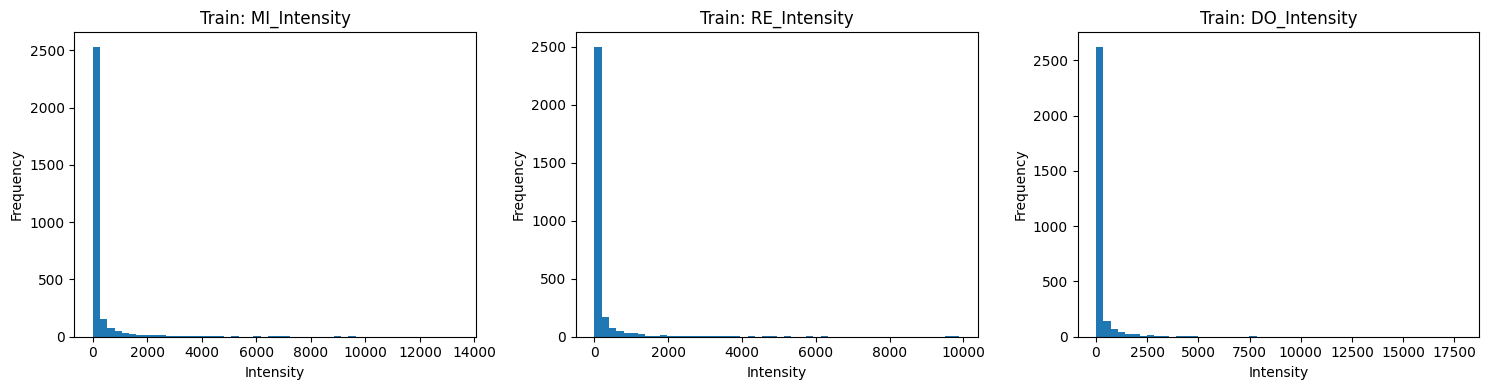

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, FEATURE_COLUMNS):
    values = train[col].to_numpy(dtype=float)
    ax.hist(values, bins=50)
    ax.set_title(f"Train: {col}")
    ax.set_xlabel("Intensity")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


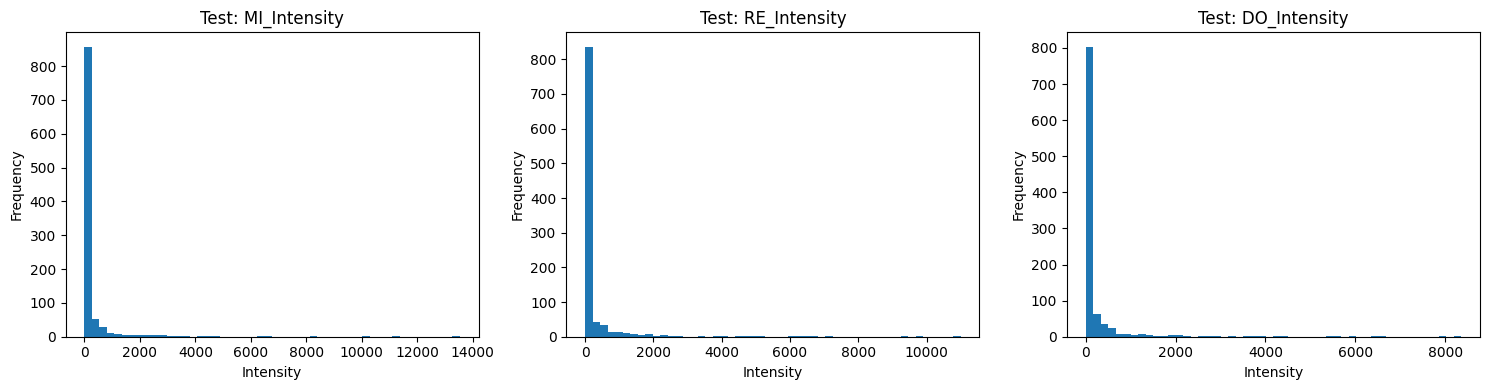

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, FEATURE_COLUMNS):
    values = test[col].to_numpy(dtype=float)
    ax.hist(values, bins=50)
    ax.set_title(f"Test: {col}")
    ax.set_xlabel("Intensity")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


In [7]:
print("Statistik train:")
display(train[FEATURE_COLUMNS].describe().T)

print("Statistik test:")
display(test[FEATURE_COLUMNS].describe().T)


Statistik train:


,count,mean,std,min,25%,50%,75%,max
MI_Intensity,2997.0,269.554369,944.377877,1.002797,3.597169,14.605961,103.796373,13386.844917
RE_Intensity,2997.0,218.150317,751.831591,1.002152,3.278844,13.259747,86.797780,9891.320534
DO_Intensity,2997.0,239.584628,876.022811,1.000098,3.187650,13.708873,94.411051,17829.787032


Statistik test:


,count,mean,std,min,25%,50%,75%,max
MI_Intensity,1000.0,246.329772,935.233681,1.003241,3.174670,13.416011,84.910896,13545.233080
RE_Intensity,1000.0,264.616971,939.078448,1.000056,3.509328,14.261752,80.814654,10993.223337
DO_Intensity,1000.0,240.032003,785.429175,1.000286,3.481127,14.187011,105.167374,8354.670137


# 5. Helper function

Bagian ini berisi fungsi pembantu yang dapat digunakan untuk menguji solusi.

Metric yang digunakan kompetisi adalah **Macro F1**. Fungsi berikut diimplementasikan secara manual sehingga peserta tidak membutuhkan `scikit-learn` atau library machine learning lainnya.

Validation set `val.csv` dapat dipakai untuk mengukur kualitas solusi Soal 1 secara lokal.


In [8]:
def confusion_matrix_manual(y_true, y_pred, labels):
    index = {label: i for i, label in enumerate(labels)}
    matrix = np.zeros((len(labels), len(labels)), dtype=int)

    for actual, predicted in zip(y_true, y_pred):
        if actual not in index:
            raise ValueError(f"Label aktual tidak dikenal: {actual}")
        if predicted not in index:
            raise ValueError(f"Label prediksi tidak dikenal: {predicted}")
        matrix[index[actual], index[predicted]] += 1

    return matrix


def macro_f1_score_manual(y_true, y_pred, labels):
    cm = confusion_matrix_manual(y_true, y_pred, labels)

    f1_values = []

    for i in range(len(labels)):
        true_positive = cm[i, i]
        false_positive = cm[:, i].sum() - true_positive
        false_negative = cm[i, :].sum() - true_positive

        denominator = (
            2 * true_positive
            + false_positive
            + false_negative
        )

        if denominator == 0:
            f1 = 0.0
        else:
            f1 = 2 * true_positive / denominator

        f1_values.append(f1)

    return float(np.mean(f1_values))


def evaluate_color_predictions(y_true, y_pred):
    score = macro_f1_score_manual(
        np.asarray(y_true),
        np.asarray(y_pred),
        COLOR_LABELS,
    )

    print("Macro F1:", round(score, 6))

    cm = confusion_matrix_manual(
        np.asarray(y_true),
        np.asarray(y_pred),
        COLOR_LABELS,
    )

    print("\nConfusion matrix (baris = aktual, kolom = prediksi):")
    display(pd.DataFrame(
        cm,
        index=COLOR_LABELS,
        columns=COLOR_LABELS,
    ))

    return score


def evaluate_type_predictions(y_true, y_pred):
    type_labels = np.array([0, 1, 2, 3])

    score = macro_f1_score_manual(
        np.asarray(y_true),
        np.asarray(y_pred),
        type_labels,
    )

    print("Macro F1:", round(score, 6))

    cm = confusion_matrix_manual(
        np.asarray(y_true),
        np.asarray(y_pred),
        type_labels,
    )

    print("\nConfusion matrix (baris = aktual, kolom = prediksi):")
    display(pd.DataFrame(
        cm,
        index=type_labels,
        columns=type_labels,
    ))

    return score


def check_submission_color(predictions):
    predictions = np.asarray(predictions)

    assert len(predictions) == len(test)
    assert np.isin(predictions, COLOR_LABELS).all()

    print("Submission Soal 1 valid.")
    print("Jumlah baris:", len(predictions))


def check_submission_type(ids, predictions):
    ids = np.asarray(ids)
    predictions = np.asarray(predictions)

    assert len(ids) == 81
    assert len(predictions) == 81
    assert len(np.unique(ids)) == 81
    assert np.isin(predictions, [0, 1, 2, 3]).all()

    print("Submission Soal 2 valid.")
    print("Jumlah alien:", len(ids))


## Contoh penggunaan evaluator validation

Contoh berikut sengaja bukan solusi kompetitif. Gunakan untuk memastikan evaluator bekerja sebelum menulis solusi sendiri.


In [9]:
# Contoh: selalu menebak "do"
demo_predictions = np.array(["do"] * len(val))

evaluate_color_predictions(
    val["Color"].to_numpy(),
    demo_predictions,
)


Macro F1: 0.039867

Confusion matrix (baris = aktual, kolom = prediksi):


,do,re,mi,fa,sol,la,si
do,6,0,0,0,0,0,0
re,10,0,0,0,0,0,0
mi,6,0,0,0,0,0,0
fa,5,0,0,0,0,0,0
sol,5,0,0,0,0,0,0
la,2,0,0,0,0,0,0
si,3,0,0,0,0,0,0


0.03986710963455149

# 6. Soal 1 — Prediksi Color

**Bobot: 50 poin**

Prediksi `Color` untuk setiap baris pada `test.csv`.

Baseline di bawah sengaja sangat sederhana: seluruh baris ditebak sebagai `do`.

> **TO DO: Tulis solusi Anda di sini.**

Solusi Anda harus mengubah fungsi `predict_color`. Anda boleh menggunakan `train`, `test`, `val`, NumPy, Pandas, Matplotlib, dan Python standard library, sesuai aturan kompetisi.


## Evaluasi lokal Soal 1

Karena `val.csv` memiliki label asli, Anda dapat menjalankan fungsi yang sama pada validation set untuk mengukur performa secara lokal.


In [10]:
# val_color_predictions = predict_color(
#     train,
#     val[FEATURE_COLUMNS],
# )

# evaluate_color_predictions(
#     val["Color"].to_numpy(),
#     val_color_predictions,
# )


In [ ]:
class knnc:
    """kNN pada log-intensitas yang distandarkan (rentang 1..13000)."""
    def __init__(self, k=11):
        self.k = k
    def fit(self, x, y):
        x = np.log10(np.asarray(x, dtype=float) + 1e-9)
        self.mean_ = x.mean(axis=0)
        self.std_ = x.std(axis=0)
        self.x = (x - self.mean_) / self.std_
        self.y = np.asarray(y)
        return self
    def predict(self, x):
        x = (np.log10(np.asarray(x, dtype=float) + 1e-9) - self.mean_) / self.std_
        dis = np.sqrt(np.sum((self.x[None, :, :] - x[:, None, :]) ** 2, axis=2))
        indices = np.argsort(dis, axis=1)
        label = self.y[indices][:, :self.k]
        return np.asarray([np.bincount(item).argmax() for item in label])


In [ ]:
def anova_f(channel_values, groups):
    """Seberapa informatif satu kanal terhadap label warna (log-domain)."""
    v = np.log10(np.asarray(channel_values, dtype=float) + 1e-9)
    g = np.asarray(groups)
    rata = v.mean()
    kelas = np.unique(g)
    antar = sum(((v[g == c].mean() - rata) ** 2) * (g == c).sum() for c in kelas)
    dalam = sum((((v[g == c] - v[g == c].mean()) ** 2).sum()) for c in kelas)
    return (antar / (len(kelas) - 1)) / (dalam / (len(v) - len(kelas)))

ALIEN_TYPES = {}
for _alien, _rows in train.groupby("Id"):
    _f = [anova_f(_rows[c], _rows["Color"]) for c in FEATURE_COLUMNS]
    ALIEN_TYPES[_alien] = 0 if min(_f) >= 10 else int(np.argmin(_f)) + 1
print("Sebaran tipe:", {t: list(ALIEN_TYPES.values()).count(t) for t in [0, 1, 2, 3]})

knc = knnc(k=11)
modifiedtrain = train.copy()
MAP = {"do":0, "re":1, "mi":2, "fa":3, "sol":4, "la":5, "si":6}
REVMAP = {0:"do", 1:"re", 2:"mi", 3:"fa", 4:"sol", 5:"la", 6:"si"}
modifiedtrain["Color"] = train["Color"].replace(MAP)
normal_ids = [a for a, t in ALIEN_TYPES.items() if t == 0]
knc.fit(train.loc[train["Id"].isin(normal_ids), FEATURE_COLUMNS],
        modifiedtrain.loc[train["Id"].isin(normal_ids), "Color"])


In [13]:
valans = knc.predict(val[["MI_Intensity", "RE_Intensity", "DO_Intensity"]])
valans = np.array([REVMAP[itm] for itm in valans])
valans


array(['do', 'sol', 'mi', 'mi', 'do', 'do', 'si', 'fa', 'mi', 'do', 'do',
       'mi', 'do', 'do', 're', 're', 're', 'fa', 'si', 'sol', 'mi', 're',
       're', 're', 'sol', 're', 're', 'do', 'fa', 're', 'mi', 'si', 'fa',
       're', 'la', 're', 'la'], dtype='<U3')

In [14]:
evaluate_color_predictions(
    val["Color"].to_numpy(),
    valans,
)

Macro F1: 0.921202

Confusion matrix (baris = aktual, kolom = prediksi):


,do,re,mi,fa,sol,la,si
do,6,0,0,0,0,0,0
re,0,10,0,0,0,0,0
mi,0,0,6,0,0,0,0
fa,0,1,0,4,0,0,0
sol,2,0,0,0,3,0,0
la,0,0,0,0,0,2,0
si,0,0,0,0,0,0,3


0.9212018140589568

In [15]:
def predict_color(train_df, test_df):
    ans = knc.predict(test_df[["MI_Intensity", "RE_Intensity", "DO_Intensity"]])
    # Baseline sederhana: seluruh stimulus diprediksi sebagai "do".
    newans = np.array([REVMAP[itm] for itm in ans])
    return np.array(newans)

# 7. Soal 2 — Klasifikasi tipe penglihatan alien

**Bobot: 50 poin**

Setiap `Id` pada `train.csv` mewakili satu alien dan muncul sebanyak 37 kali.

Untuk setiap alien, tentukan:

- `0` = normal
- `1` = tanpa sel kerucut mi
- `2` = tanpa sel kerucut re
- `3` = tanpa sel kerucut do

Baseline di bawah sengaja sangat sederhana: semua alien ditebak sebagai tipe `1` (tanpa sel kerucut mi).

> **TO DO: Tulis solusi Anda di sini.**

Fungsi `classify_alien_type` harus mengembalikan satu tipe untuk setiap 81 `Id` unik.


In [16]:
# from collections import defaultdict
# ans = []
# unique_ids = train["Id"].drop_duplicates().to_numpy()
# for ids in unique_ids:
#     for indx, r in train.iterrows():
#         rid = r["Id"]
#         if rid == ids:
#             data = np.asarray(r[["MI_Intensity", "RE_Intensity","DO_Intensity"]])
#             idx = np.argmax(data)
#             if data[idx] >= 1000:
#                 ans.append(idx.astype(int)+1)
#             else:
#                 ans.append(0)
#             break

In [17]:
class kmeans:
    def fit(self, x):
        x = np.asarray(x)
        self.k = 4
        randidx = np.random.choice(len(x), self.k, replace=False)
        centroid = x[randidx]
        while True:
            dis = np.sqrt(np.sum((x[:, None, :] - centroid[None, :, :])**2, axis=2))
            label = np.argmin(dis, axis=1)
            newcentroid = np.array([np.mean(x[label == k], axis=0)for k in range(self.k)])
            if np.array_equal(newcentroid, centroid):
                break
            centroid = newcentroid
        return label

In [18]:
km = kmeans()
ans =km.fit(train[["MI_Intensity", "RE_Intensity","DO_Intensity"]])

In [19]:
from collections import defaultdict
def classify_alien_type(train_df):
    unique_ids = train_df["Id"].drop_duplicates().to_numpy()
    ke = defaultdict(list)
    mi = defaultdict(int)
    re = defaultdict(int)
    do = defaultdict(int)
    cnt = defaultdict(int)
    for indx, r in train.iterrows():
        rid = r["Id"]
        mii = r["MI_Intensity"]
        rei = r["RE_Intensity"]
        doi = r["DO_Intensity"]
        cnt[rid] += 1
        mi[rid]+=mii
        re[rid]+=rei
        do[rid]+=doi
    modifpos = []
    for ida in unique_ids:
        pmi = mi[ida]/cnt[ida]
        pre = re[ida]/cnt[ida]
        pdo = do[ida]/cnt[ida]
        modifpos.append([pmi, pre, pdo])
    ans = km.fit(modifpos)
    return pd.DataFrame({
        "Id": unique_ids,
        "Type": ans
    })


    # Baseline sederhana: seluruh alien diprediksi sebagai tipe 1.
    # ans =km.fit(train_df[["MI_Intensity", "RE_Intensity","DO_Intensity"]])
    # unique_ids = train_df["Id"].drop_duplicates().to_numpy()
    # ke = defaultdict(list)
    # reans = []
    # for indx, r in train.iterrows():
    #     rid = r["Id"]
    #     ke[rid].append(ans[indx])
    # for key, val in ke.items():
    #     cnt = np.bincount(val).argmax()
    #     reans.append(cnt)
    # return pd.DataFrame({
    #     "Id": unique_ids,
    #     "Type": reans
    # })


# for ids in unique_ids:
    #     for indx, r in train.iterrows():
    #         rid = r["Id"]
    #         if rid == ids:
    #             data = np.asarray(r[["MI_Intensity", "RE_Intensity","DO_Intensity"]])
    #             idx = np.argmax(data)
    #             if data[idx] >= 1000:
    #                 ans.append(idx.astype(int)+1)
    #             else:
    #                 ans.append(0)
    #             break
    # return pd.DataFrame({
    #     "Id": unique_ids,
    #     "Type": ans
    # })
file = classify_alien_type(train)
file

,Id,Type
0,ALIEN_53,0
1,ALIEN_57,2
2,ALIEN_65,1
3,ALIEN_40,3
4,ALIEN_25,3
...,...,...
76,ALIEN_16,3
77,ALIEN_75,2
78,ALIEN_52,3
79,ALIEN_76,2


In [ ]:
from collections import defaultdict
def classify_alien_type(train_df):
    """Tipe dari ALIEN_TYPES (F-stat, dihitung saat fit warna). 1=tanpa mi, 2=tanpa re, 3=tanpa do."""
    unique_ids = train_df["Id"].drop_duplicates().to_numpy()
    return pd.DataFrame({"Id": unique_ids,
                         "Type": [ALIEN_TYPES[i] for i in unique_ids]})


file = classify_alien_type(train)
FILENAME = f"submission.csv"
JALUR_SUBMISSION = (
    Path(f"/kaggle/working/{FILENAME}")
    if Path("/kaggle/working").exists()
    else Path(f"{FILENAME}")
)
type_predictions = classify_alien_type(train)
check_submission_type(
    type_predictions["Id"].to_numpy(),
    type_predictions["Type"].to_numpy(),
)
test_color_predictions = predict_color(train, test)
submission = sample_submission.copy()
color_mask = submission["id"].str.startswith("COLOR_")
alien_mask = submission["id"].str.startswith("ALIEN_")
if submission.loc[color_mask, "id"].tolist() != test["id"].tolist():
    raise ValueError("Urutan ID warna tidak cocok dengan test.csv")
submission.loc[color_mask, "answer"] = test_color_predictions.astype(str)

type_by_id = type_predictions.set_index("Id")["Type"].astype(str)
submission.loc[alien_mask, "answer"] = submission.loc[alien_mask, "id"].map(type_by_id)
if submission["answer"].isna().any():
    raise ValueError("Masih terdapat ID tanpa prediksi")

submission.to_csv(JALUR_SUBMISSION, index=False)
print("Submission ditulis ke:", JALUR_SUBMISSION)
print("Jumlah baris:", len(submission))
display(submission.head())
display(submission.tail())